# Economics 5040 - Week 2
## Answer Key

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import matrix_rank, lstsq

# Problem 1. CARA Utility and the Price of Risk

For
$$
u(w)=\frac{1-e^{-\gamma w}}{\gamma},
$$
we have $u'(w)=e^{-\gamma w}$ and $u''(w)=-\gamma e^{-\gamma w}$. Hence
$$
A(w)=-\frac{u''}{u'}=\gamma,\qquad
\rho(w)=-w\frac{u''}{u'}=\gamma w.
$$


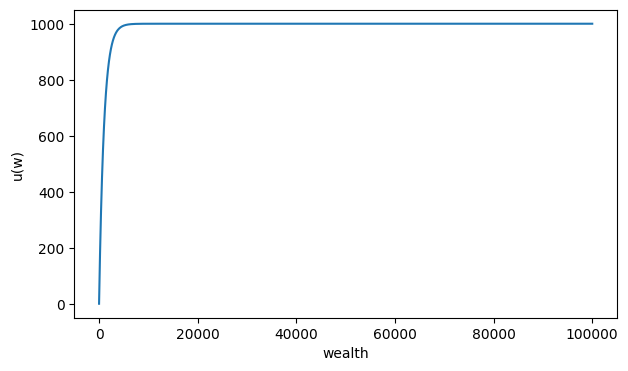

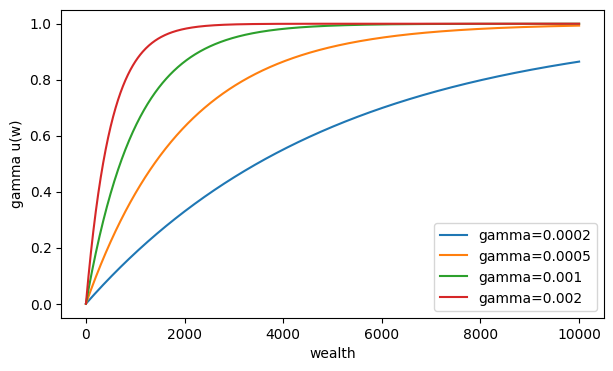

EU gamble 999.9999999999063 U(no gamble) 999.9999999999064 CE final wealth 29998.648075081146 risk premium 6.351924918853911
loss 1000.0 EU Devil 999.9999999998729 U refuse 999.9999999999064 accept? False
loss 500.0 EU Devil 999.9999999999228 U refuse 999.9999999999064 accept? True


In [2]:
gamma=1/1000
def cara(w,gamma):
    return (1-np.exp(-gamma*np.asarray(w)))/gamma

w=np.linspace(0,100000,1000)
plt.figure(figsize=(7,4))
plt.plot(w,cara(w,gamma))
plt.xlabel("wealth"); plt.ylabel("u(w)"); plt.show()

# Curvature comparison on a scale where the functions can actually be seen.
gammas=[1/5000,1/2000,1/1000,1/500]
wshort=np.linspace(0,10000,800)
plt.figure(figsize=(7,4))
for g in gammas:
    # normalize by each upper bound to compare shape rather than scale
    plt.plot(wshort, cara(wshort,g)*g, label=f"gamma={g:g}")
plt.xlabel("wealth"); plt.ylabel("gamma u(w)")
plt.legend(); plt.show()

w0=30000.
final=np.array([w0-100,w0+110])
EU=.5*cara(final[0],gamma)+.5*cara(final[1],gamma)
U0=cara(w0,gamma)
CE=-np.log(1-gamma*EU)/gamma
RP=final.mean()-CE
print("EU gamble",EU,"U(no gamble)",U0,"CE final wealth",CE,"risk premium",RP)

ulim=1/gamma
# Devil's offer: compare a 50-50 lottery between w0-L and unbounded wealth
for loss in [1000.,500.]:
    EUdevil=.5*cara(w0-loss,gamma)+.5*ulim
    print("loss",loss,"EU Devil",EUdevil,"U refuse",U0,"accept?",EUdevil>U0)


For $\gamma=1/1000$, utility is bounded above by $1/\gamma=1000$. The Devil's Offer exploits that boundedness: once the upside is near the utility ceiling, making the upside still larger contributes almost no additional utility. This is an unusually stark implication of CARA utility.

# Problem 2. From Outcomes to Expected Utility

Normalize log utility by
$$
\tilde u(x)=\frac{\log x-\log x_1}{\log x_3-\log x_1}.
$$
Then $\tilde u(x_i)$ is the probability of the best outcome in the best-worst lottery equivalent to $x_i$.

In [3]:
x=np.array([25.,100.,225.])
L=np.array([.25,.50,.25])
ulog=np.log(x)
un=(ulog-ulog[0])/(ulog[-1]-ulog[0])
print("normalized utility",un)
print("probability on best in reduced L =",L@un)

# Choose M
M=np.array([.5,.1,.4])
print("EU L, M",L@un,M@un)
print("Affine:",L@(7+3*un),M@(7+3*un))

# Search for a pair whose ranking reverses under exp(normalized utility)
rng=np.random.default_rng(4)
for _ in range(200000):
    A=rng.dirichlet(np.ones(3)); B=rng.dirichlet(np.ones(3))
    d1=A@un-B@un
    d2=A@np.exp(un)-B@np.exp(un)
    if d1*d2 < 0:
        print("counterexample A",A,"B",B)
        print("EU difference",d1,"transformed difference",d2)
        break


normalized utility [0.         0.63092975 1.        ]
probability on best in reduced L = 0.5654648767857289
EU L, M 0.5654648767857289 0.4630929753571458
Affine: 8.696394630357187 8.389278926071437
counterexample A [0.51348387 0.15651734 0.32999879] B [0.3832059  0.43549677 0.18129732]
EU difference -0.02731495592781702 transformed difference 0.010188484792598151


# Problem 3. State Prices

With log utility,
$$
q_s=\beta\pi_s\frac{c_0}{c_1(s)},\qquad
m_s=\beta\frac{c_0}{c_1(s)}.
$$

m = [0.64 1.92] q = [0.32 0.96] q/pi = [0.64 1.92]


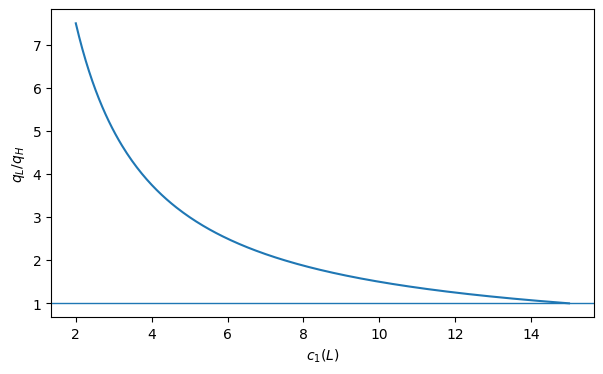

In [4]:
beta=.96; pi=np.array([.5,.5]); c0=10.; c1=np.array([15.,5.])
m=beta*c0/c1
q=pi*m
print("m =",m,"q =",q,"q/pi =",q/pi)

cLgrid=np.linspace(2,15,300)
ratio=(beta*pi[1]*c0/cLgrid)/q[0]
plt.figure(figsize=(7,4))
plt.plot(cLgrid,ratio)
plt.axhline(1,linewidth=1)
plt.xlabel(r"$c_1(L)$"); plt.ylabel(r"$q_L/q_H$"); plt.show()


# Problem 4. Assets as Bundles of State-Contingent Claims

In [5]:
assets={"A":np.array([1.,1.]),"B":np.array([2.,0.]),"C":np.array([0.,2.]),"D":np.array([3.,1.])}
Rf=1/q.sum()
results={}
print("Rf =",Rf)
for name,xpay in assets.items():
    p=q@xpay
    R=xpay/p
    ER=pi@R
    results[name]=(p,R,ER)
    print(name,"p",p,"R",R,"E[R]",ER,"E[mx]",pi@(m*xpay),"E[mR]",pi@(m*R))


Rf = 0.78125
A p 1.28 R [0.78125 0.78125] E[R] 0.78125 E[mx] 1.28 E[mR] 1.0
B p 0.64 R [3.125 0.   ] E[R] 1.5625 E[mx] 0.64 E[mR] 1.0
C p 1.92 R [0.         1.04166667] E[R] 0.5208333333333334 E[mx] 1.92 E[mR] 1.0
D p 1.92 R [1.5625     0.52083333] E[R] 1.0416666666666667 E[mx] 1.92 E[mR] 1.0


# Problem 5. What Kind of Risk Commands a Premium?

In [6]:
for name in ["B","C","D"]:
    p,R,ER=results[name]
    cov=pi@((m-pi@m)*(R-ER))
    print(name,"cov",cov,"premium",ER-Rf,"rhs",-Rf*cov)

D=assets["D"]
E=np.array([1.,3.])   # same expected payoff 2, tilted toward L
F=np.array([3.5,.5])  # same expected payoff 2, tilted further toward H
for name,xpay in [("D",D),("E",E),("F",F)]:
    p=q@xpay; R=xpay/p
    print(name,"expected payoff",pi@xpay,"price",p,"expected return",pi@R)


B cov -1.0 premium 0.78125 rhs 0.78125
C cov 0.33333333333333337 premium -0.26041666666666663 rhs -0.2604166666666667
D cov -0.3333333333333333 premium 0.26041666666666674 rhs 0.26041666666666663
D expected payoff 2.0 price 1.92 expected return 1.0416666666666667
E expected payoff 2.0 price 3.1999999999999997 expected return 0.625
F expected payoff 2.0 price 1.6 expected return 1.25


Assets that pay relatively more in the low-consumption state are valuable insurance: they have higher prices and lower expected returns. Assets tilted toward the high-consumption state do the opposite. Priced risk is covariance with marginal utility, not variance by itself.

# Problem 6. Complete and Incomplete Markets

In [7]:
I=np.eye(3)
print("Arrow rank",matrix_rank(I))
x=np.array([4.,-1.,2.])
print("replicating Arrow portfolio",np.linalg.solve(I,x))

bond=np.array([1.,1.,1.]); asset=np.array([2.,1.,0.])
X=np.column_stack([bond,asset])
target=np.array([0.,1.,0.])
print("rank",matrix_rank(X))
theta,resid,_,_=lstsq(X,target,rcond=None)
print("least squares theta",theta)
print("fitted",X@theta)
print("residual vector",target-X@theta)


Arrow rank 3
replicating Arrow portfolio [ 4. -1.  2.]
rank 2
least squares theta [3.33333333e-01 3.20493781e-17]
fitted [0.33333333 0.33333333 0.33333333]
residual vector [-0.33333333  0.66666667 -0.33333333]


Attainable payoffs are
$$
(\theta_b+2\theta_a,\theta_b+\theta_a,\theta_b),
$$
so they satisfy
$$
x_1-2x_2+x_3=0.
$$
The target $(0,1,0)$ violates this condition. The market therefore lacks a security combination that isolates the middle state.

# Problem 7. Synthesis - Guide

A strong answer should explain the progression from the Week 1 price of consumption across dates to a vector of prices for consumption across future states. It should explain that Arrow prices satisfy
$$
q_s=\pi_s m_s,
$$
that an arbitrary asset is a bundle of state claims,
$$
p=\sum_s q_sx_s=E[mx],
$$
and that the risk-free asset bundles one unit of every state claim,
$$
1/R_f=\sum_s q_s=E[m].
$$
It should also explain why completeness is a statement about whether traded payoff vectors span the full state space, and why marginal utility makes consumption in bad states especially valuable.